In [1]:
import json
import os

import requests
from dotenv import load_dotenv
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
def jprint(obj):
    text = json.dumps(obj, sort_keys=True, indent=4)
    print(text)


load_dotenv()
WEATHERAPI_KEY = os.getenv("WEATHERAPI_API_KEY")

if WEATHERAPI_KEY is None:
    raise ValueError("WEATHERAPI_KEY is missing from .env")

In [3]:
def fetch_forecast(city, days):
    """Call the forecast endpoint and return the parsed JSON"""
    url = "https://api.weatherapi.com/v1/forecast.json"
    params = {
        "key": WEATHERAPI_KEY, 
        "q": city, 
        "days": days
    }
    response = requests.get(url, params=params, timeout=10)
    response.raise_for_status()
    return response.json()

In [4]:
def hours_to_dataframe(data):
	"""Turn the nested forecast JSON into one flat row per hour"""
	all_hours = []
    
	for day in data["forecast"]["forecastday"]:
		for hour in day["hour"]:
			all_hours.append({
				"time": hour["time_epoch"],
				"temp_c": hour["temp_c"],
				"wind_kph": hour["wind_kph"],
				"humidity": hour["humidity"],
				"chance_of_rain": hour["chance_of_rain"],
				"condition": hour["condition"]["text"]
			})

	df = pd.DataFrame(all_hours)
	df["time"] = pd.to_datetime(df["time"], unit='s', utc=True)
	df["date"] = df["time"].dt.date
	return df

In [5]:
def	get_daily_temp_stats(df):
    """Return the minimum, mean and maximum temperature for each day"""
    return df.groupby("date")["temp_c"].agg(["min", "mean", "max"])

In [6]:
def count_rainy_hours(df, threshold=50):
	"""Count per day the hours where the chance of rain is above the `threshold` percent"""
	return df[df["chance_of_rain"] > threshold].groupby("date").size()

In [7]:
city = "paris"
days = 3

data = fetch_forecast(city, days)
df = hours_to_dataframe(data)
daily_stats = get_daily_temp_stats(df)
rainy_hours = count_rainy_hours(df, 80)

print(daily_stats)
print(rainy_hours)

start = df["time"].min().strftime("%d %b")
end = df["time"].max().strftime("%d %b %Y")
file_stem = f"{city.lower().replace(' ', '_')}_temp_{df['time'].min():%Y-%m-%d}"

             min       mean   max
date                             
2026-11-14   5.7   5.700000   5.7
2026-11-15   6.0   9.254167  12.4
2026-11-16   9.5  10.158333  11.0
2026-11-17  11.2  13.478261  16.5
date
2026-11-16    2
2026-11-17    2
dtype: int64


In [8]:
os.makedirs("plots", exist_ok=True)
os.makedirs("data", exist_ok=True)

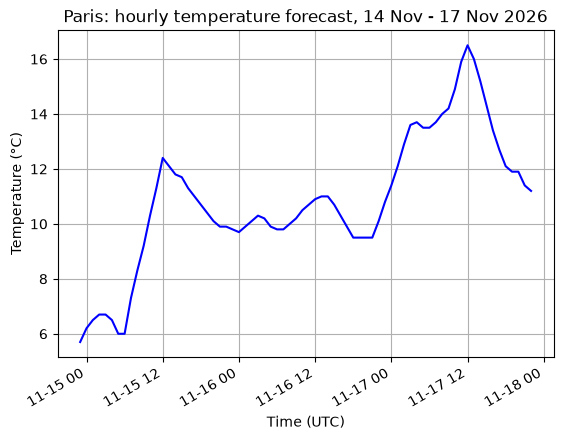

In [9]:
plt.plot(df["time"], df["temp_c"], linestyle='-', color='blue')
plt.title(f"{city.title()}: hourly temperature forecast, {start} - {end}")
plt.xlabel("Time (UTC)")
plt.ylabel("Temperature (°C)")
plt.grid()
plt.gcf().autofmt_xdate()
plt.savefig(f"plots/{file_stem}.png", dpi=100)
plt.show()

In [10]:
df.to_csv(f"data/{file_stem}.csv", index=False)

In [13]:
ldf = pd.read_csv(f"data/{file_stem}.csv", parse_dates=['time'])
ldf['date'] = ldf['time'].dt.date
daily_stats = get_daily_temp_stats(ldf)
print(daily_stats)

             min       mean   max
date                             
2026-11-14   5.7   5.700000   5.7
2026-11-15   6.0   9.254167  12.4
2026-11-16   9.5  10.158333  11.0
2026-11-17  11.2  13.478261  16.5
